# ML model diagnostics — Fare prediction (`fare_prediction`)

Diagnostic notebook for the **fare** use case (label `fare_amount`).

No re-training: loads the `@champion` model from the MLflow Model Registry and analyses it over the gold tables.

> One of three per-use-case diagnostic notebooks (`fare` / `duration` / `demand`). `USE_CASE` is pinned below; the analysis body is identical across the three.

Sections:
1. Parameters + setup (Spark + MLflow).
2. Load `@champion` model + registered metadata.
3. Reconstruct splits (`train` / `val` / `common_test`) and measure each.
4. Per-year breakdown — TRAIN_VAL_YEARS (in-sample-ish) vs TEST_YEAR (held out, the drift signal).
5. Predicted vs Actual on `common_test`.
6. Residuals.
7. Feature importance (algorithm-agnostic).
8. Phase 2 — More-data A vs B.
9. Baseline vs champion.
10. Conclusions.

## 1. Parameters

`USE_CASE` is pinned to `fare` for this notebook — one of the three per-use-case diagnostics.

In [1]:
USE_CASE = "fare"   # pinned for this notebook

from ml.train import USE_CASES
from ml.splits import TEST_YEAR, TRAIN_VAL_YEARS

cfg = USE_CASES[USE_CASE]
EXPERIMENT = cfg["experiment"]
SOURCE     = cfg["source"]
LABEL      = cfg["label_col"]
YEAR_COL   = cfg["year_col"]
print(f"USE_CASE={USE_CASE}  EXPERIMENT={EXPERIMENT}  LABEL={LABEL}")
print(f"Split: TRAIN_VAL_YEARS={TRAIN_VAL_YEARS}  TEST_YEAR={TEST_YEAR}")

USE_CASE=fare  EXPERIMENT=fare_prediction  LABEL=fare_amount
Split: TRAIN_VAL_YEARS=[2023, 2024]  TEST_YEAR=2025


In [2]:
import mlflow
import mlflow.spark
from mlflow import MlflowClient
from pyspark.ml.feature import VectorAssembler
from pyspark.sql.functions import col
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ml.splits import add_cyclical_features, make_splits
from ml.tracking import (
    compute_baseline_metrics,
    evaluate_predictions,
    evaluate_regression,
    get_ml_spark,
    setup_mlflow,
)

spark = get_ml_spark(f"ml-{USE_CASE}-diagnostics")
setup_mlflow(EXPERIMENT)
client = MlflowClient()
spark.version

26/06/02 20:57:30 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


'3.5.8'

## 2. Load the `@champion` model from the Registry

Resolving via the `@champion` alias always returns the latest promoted version. For older versions, replace `"champion"` with the version number:
`client.get_model_version(EXPERIMENT, "3")`.

In [3]:
mv = client.get_model_version_by_alias(name=EXPERIMENT, alias="champion")
source_run = client.get_run(mv.run_id)
print(f"Registered model: {EXPERIMENT} v{mv.version}")
print(f"Source run ID:    {mv.run_id}")
print(f"Run name:         {source_run.data.tags.get('mlflow.runName')}")
print(f"Algorithm:        {source_run.data.tags.get('algorithm')}")
print(f"Phase:            {source_run.data.tags.get('phase')}")
print(f"Training data:    {source_run.data.tags.get('training_data')}")
print(f"Created by:       {source_run.data.tags.get('created_by')}")
print(f"Started:          {pd.Timestamp(source_run.info.start_time, unit='ms')}")
print(f"\nDescription:\n  {mv.description or '(none)'}\n")
print("Version tags:")
for k, v in sorted(mv.tags.items()):
    print(f"  {k}: {v}")

Registered model: fare_prediction v2
Source run ID:    a54de13ee05845569da972f2946bc264
Run name:         train-gbt
Algorithm:        gbt
Phase:            training
Training data:    [2023, 2024]
Created by:       jgalanllano
Started:          2026-06-01 16:32:39.759000

Description:
  Run name: train-gbt. Algorithm: gbt. Phase: training.
Params: {'maxIter': 50, 'maxDepth': 6, 'stepSize': 0.1, 'subsamplingRate': 1.0, 'featureSubsetStrategy': 'all', 'maxBins': 300, 'seed': 42}.
Source: nessie.nyc.yellow_taxi_trips (Nessie main hash=5a5db2c90868, snapshot_id=3080913557231476204). Target: fare_amount.
Training data: [2023, 2024].
Numerical features (base): trip_distance, passenger_count, pickup_year, pickup_month, pickup_week, pickup_dow, pickup_hour.
Categorical features: pu_location_id, do_location_id, vendor_id, ratecode_id, payment_type.
Scores: val_rmse=3.5420, common_test_rmse=3.8468, common_test_mae=1.7003, common_test_r2=0.9335. Baseline common_test_rmse=11.2947.

Version tags:
  

In [4]:
metrics_df = pd.DataFrame.from_dict(source_run.data.metrics, orient='index', columns=['value'])
params_df  = pd.DataFrame.from_dict(source_run.data.params,  orient='index', columns=['value'])
display(metrics_df.sort_index())
display(params_df.sort_index())

,value
common_test_mae,1.700298
common_test_r2,0.933520
common_test_rmse,3.846776
cv_avg_rmse_grid_0,3.688823
cv_avg_rmse_grid_1,3.598882
cv_avg_rmse_grid_2,3.547515
cv_avg_rmse_grid_3,3.821432
cv_best_avg_rmse,3.547515
train_mae,1.591173
train_r2,0.945350


,value
best_featureSubsetStrategy,all
best_grid_idx,2
best_maxBins,300
best_maxDepth,6
best_maxIter,50
best_seed,42
best_stepSize,0.1
best_subsamplingRate,1.0
categorical_cols,"pu_location_id,do_location_id,vendor_id,rateco..."
common_test_count,8080039


In [5]:
model_uri = f"models:/{EXPERIMENT}@champion"
# mlflow.spark.load_model stages the model under a driver-local /tmp path the
# worker executors cannot see (cluster default FS is file://, so MLflow never
# copies to dfs_tmpdir) -> PipelineModel.load throws FileNotFoundException on the
# executors. Instead download the model and place its sparkml dir on the shared
# ./src bind mount (same path on every container, workers ro) and load via file://.
import os, shutil
from mlflow.artifacts import download_artifacts
from pyspark.ml import PipelineModel

local_model = download_artifacts(artifact_uri=model_uri)
shared_dir = "/opt/spark/src/.tmp_ingest/champion_sparkml"
shutil.rmtree(shared_dir, ignore_errors=True)
shutil.copytree(os.path.join(local_model, "sparkml"), shared_dir)
model = PipelineModel.load(f"file://{shared_dir}")
for i, stage in enumerate(model.stages):
    print(f"{i}: {type(stage).__name__}")

0: StringIndexerModel
1: StringIndexerModel
2: StringIndexerModel
3: StringIndexerModel
4: StringIndexerModel
5: VectorAssembler
6: VectorIndexerModel
7: GBTRegressionModel


## 3. Reconstruct splits + per-split metrics

`make_splits` uses `seed=42` (same as the training script), so train / val / common_test are reproducible. We also rebuild the same derived columns (cyclical sin/cos for non-tree algos, label filter for `duration`) **and reapply the same Bernoulli sample** (`sample_fraction` from the source run's params, `seed=42`) so the row counts here match the version tags from training time.

In [6]:
# Reapply the SAME sample (fraction + seed=42) that the champion was trained
# with, so the reconstructed train/val/common_test counts match the registered
# version tags. The fraction lives on the source run's params as
# `sample_fraction`; older runs (pre-sampling) don't have it -> read as full data.
cols_to_keep = [LABEL, *cfg["numerical_cols"], *cfg["categorical_cols"]]
df = spark.table(SOURCE).select(*cols_to_keep)
if cfg["label_filter_predicate"] is not None:
    df = df.filter(cfg["label_filter_predicate"](col(LABEL)))

run_sample_fraction = source_run.data.params.get("sample_fraction")
if run_sample_fraction is not None:
    sf = float(run_sample_fraction)
    if 0.0 < sf < 1.0:
        df = df.sample(sf, seed=42)
        print(f"Reapplied training-time sample: fraction={sf:.2f}, seed=42")
    else:
        print(f"sample_fraction={sf} -> no sampling.")
else:
    print("Source run has no sample_fraction param (pre-sampling vintage) -> using full data.")

df, _ = add_cyclical_features(df, cfg["numerical_cols"])
train, val, common_test = make_splits(df, YEAR_COL)
for s in (train, val, common_test):
    s.cache()

print("Split sizes:")
for name, s in (('train', train), ('val', val), ('common_test', common_test)):
    print(f"  {name:<12} {s.count():>12,} rows")

print(f"\ntrain + val = TRAIN_VAL_YEARS {TRAIN_VAL_YEARS}")
print(f"common_test = TEST_YEAR {TEST_YEAR} (fully held out)")

print("\nChampion metrics per split:")
print(f"  {'split':<12} {'rmse':>12} {'mae':>12} {'r2':>12}")
for name, s in (('train', train), ('val', val), ('common_test', common_test)):
    m = evaluate_regression(model, s, LABEL)
    print(f"  {name:<12} {m['rmse']:>12.4f} {m['mae']:>12.4f} {m['r2']:>12.4f}")

sample_fraction=1.0 -> no sampling.
Split sizes:
  train          13,865,445 rows
  val             2,447,132 rows
  common_test     8,080,039 rows

train + val = TRAIN_VAL_YEARS [2023, 2024]
common_test = TEST_YEAR 2025 (fully held out)

Champion metrics per split:
  split                rmse          mae           r2


  train              3.4636       1.5924       0.9449
  val                3.4676       1.5955       0.9447
  common_test        3.8468       1.7003       0.9335


## 4. Per-year breakdown — TRAIN_VAL_YEARS (in-sample-ish) vs TEST_YEAR (drift signal)

With the last-year holdout split, the honest out-of-time signal is the metric on `common_test = TEST_YEAR` ({TEST_YEAR}). To put it in context, score the champion on every year in the gold table and compare:

- **TRAIN_VAL_YEARS** rows are mostly seen during training, so their RMSE is closer to an *in-sample* number (a small slice of each year is in `val`, but most is in `train`). They show how well the model fits the training distribution.
- **TEST_YEAR** rows are fully held out — never seen during training or selection. The gap between TEST_YEAR's RMSE and the TRAIN_VAL_YEARS RMSEs is the drift signal: a small gap means the model generalizes to the future year; a large gap means the test year drifts away from the training distribution.

,year,role,n,rmse,mae,r2
0,2023,TRAIN_VAL (in-sample-ish),8323188,3.254023,1.513219,0.950616
1,2024,TRAIN_VAL (in-sample-ish),7989389,3.670331,1.675812,0.939146
2,2025,TEST (held out),8080039,3.846776,1.700298,0.933520


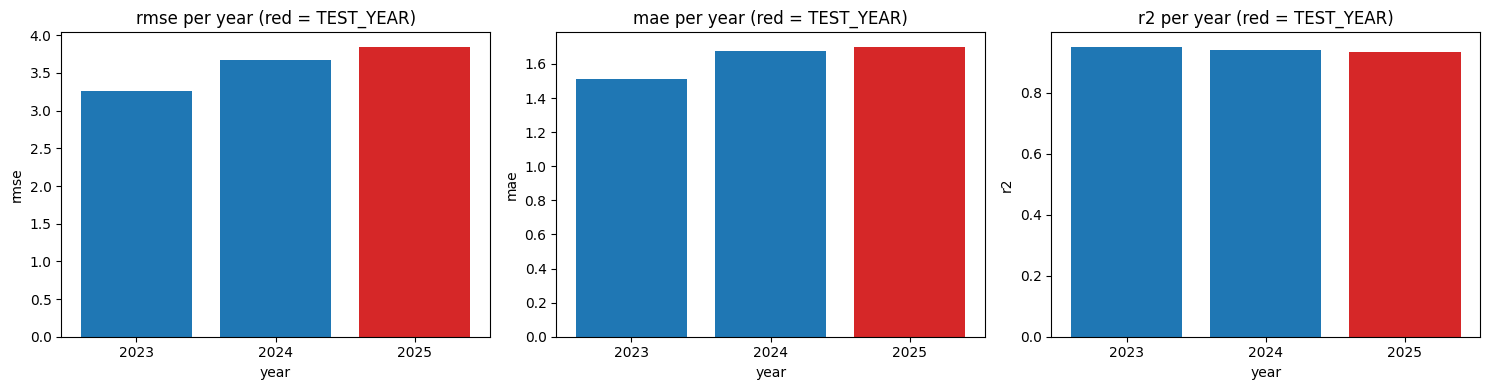

In [7]:
# Score the champion on every year — union(train, val, common_test) covers
# the full gold table at the projected columns we trained on.
full_df = train.unionByName(val).unionByName(common_test)
year_pred = model.transform(full_df).select(YEAR_COL, LABEL, 'prediction').cache()
years = sorted(r[YEAR_COL] for r in year_pred.select(YEAR_COL).distinct().collect())
rows = []
for y in years:
    yr = year_pred.filter(col(YEAR_COL) == y).select(LABEL, 'prediction')
    n = yr.count()
    if n == 0:
        continue
    m = evaluate_predictions(yr, LABEL)
    rows.append({
        'year': y,
        'role': 'TEST (held out)' if y == TEST_YEAR else 'TRAIN_VAL (in-sample-ish)',
        'n': n,
        **m,
    })
year_pred.unpersist()
per_year = pd.DataFrame(rows)
display(per_year)

# Bar plot. TEST_YEAR highlighted in red so the drift gap is visually obvious.
bar_colors = ['#d62728' if y == TEST_YEAR else '#1f77b4' for y in per_year['year']]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ('rmse', 'mae', 'r2')):
    ax.bar(per_year['year'].astype(str), per_year[metric], color=bar_colors)
    ax.set_xlabel('year')
    ax.set_ylabel(metric)
    ax.set_title(f'{metric} per year (red = TEST_YEAR)')
plt.tight_layout()

## 5. Predicted vs Actual on `common_test`

A 5 % sample of `common_test` brought to pandas for plotting. Points should align near `y = x`; systematic curvature or bias indicates miscalibration.

In [8]:
sample_fraction = 0.05
pred_full = model.transform(common_test).select(LABEL, 'prediction')
pdf = pred_full.sample(sample_fraction, seed=42).toPandas()
pdf['residual'] = pdf[LABEL] - pdf['prediction']
print(f"common_test sample: {len(pdf):,} rows ({sample_fraction:.0%})")
pdf.describe()

common_test sample: 404,507 rows (5%)


,fare_amount,prediction,residual
count,404507.000000,404507.000000,404507.000000
mean,16.113671,16.307706,-0.194035
std,14.910179,14.524410,3.866764
min,0.010000,-2.878814,-118.324932
25%,8.600000,8.730879,-1.337150
50%,12.100000,12.235835,-0.335992
75%,17.700000,17.686257,0.695720
max,367.700000,214.766180,200.506062


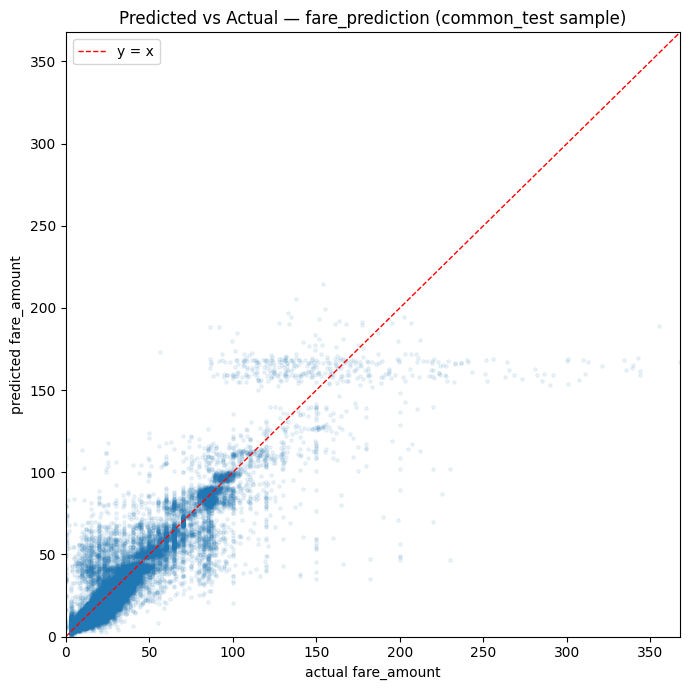

In [9]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(pdf[LABEL], pdf['prediction'], alpha=0.08, s=6)
lim = float(max(pdf[LABEL].max(), pdf['prediction'].max()))
ax.plot([0, lim], [0, lim], 'r--', linewidth=1, label='y = x')
ax.set_xlabel(f'actual {LABEL}')
ax.set_ylabel(f'predicted {LABEL}')
ax.set_title(f'Predicted vs Actual \u2014 {EXPERIMENT} (common_test sample)')
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.legend()
plt.tight_layout()

## 6. Residuals

- **Residual vs prediction** \u2014 horizontal bands = homoscedastic error (good); a funnel = heteroscedasticity.
- **Histogram of residuals** \u2014 should be centred on 0 and symmetric. Skew = systematic over/under-prediction.

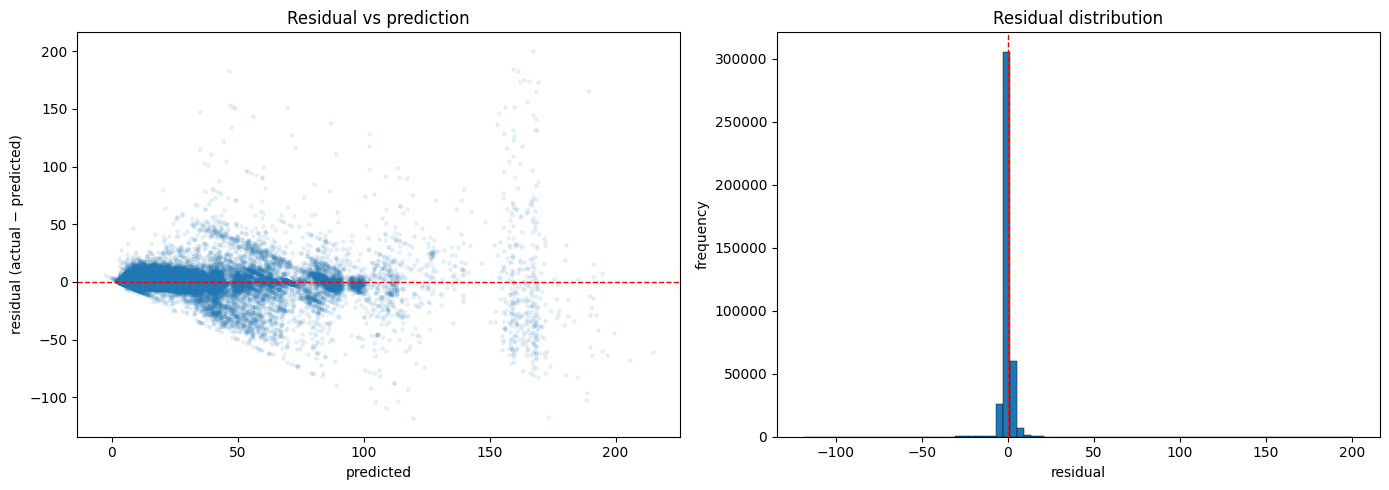

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(pdf['prediction'], pdf['residual'], alpha=0.08, s=6)
axes[0].axhline(0, color='r', linestyle='--', linewidth=1)
axes[0].set_xlabel('predicted')
axes[0].set_ylabel('residual (actual \u2212 predicted)')
axes[0].set_title('Residual vs prediction')
axes[1].hist(pdf['residual'], bins=80, edgecolor='black', linewidth=0.3)
axes[1].axvline(0, color='r', linestyle='--', linewidth=1)
axes[1].set_xlabel('residual')
axes[1].set_ylabel('frequency')
axes[1].set_title('Residual distribution')
plt.tight_layout()

## 7. Feature importance

- **GBT / RFR** — `featureImportances` (mean impurity reduction). Both tree ensembles expose the same attribute.
- **GLR** — `abs(coefficients)`. GLR features are StandardScaled, so magnitudes are comparable across columns.

,feature,importance
0,ratecode_id_idx,0.618416
1,trip_distance,0.226054
2,do_location_id_idx,0.063185
3,pu_location_id_idx,0.047219
4,pickup_hour,0.022425
5,pickup_dow,0.011627
6,payment_type_idx,0.004620
7,pickup_week,0.003372
8,pickup_year,0.001537
9,vendor_id_idx,0.000976


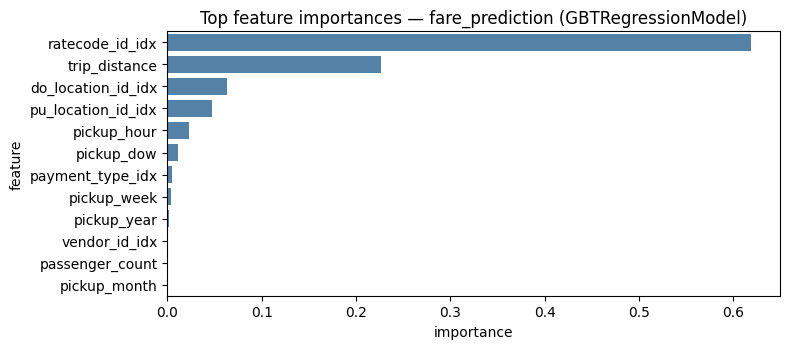

In [11]:
final = model.stages[-1]
algorithm = type(final).__name__
asm = next((s for s in model.stages if isinstance(s, VectorAssembler) and s.getOutputCol() == 'assembled_features'), None)
inputs = list(asm.getInputCols()) if asm is not None else None

if hasattr(final, 'featureImportances'):
    values = final.featureImportances.toArray(); metric_name = 'importance'
elif hasattr(final, 'coefficients'):
    values = abs(final.coefficients.toArray()); metric_name = 'abs_coef'
else:
    raise RuntimeError(f'No featureImportances/coefficients available for {algorithm}')

label_col = 'feature' if inputs is not None and len(inputs) == len(values) else 'feature_idx'
labels = inputs if label_col == 'feature' else list(range(len(values)))
fi = (
    pd.DataFrame({label_col: labels, metric_name: values})
    .sort_values(metric_name, ascending=False)
    .reset_index(drop=True)
)
top = fi.head(30)
display(top)

fig, ax = plt.subplots(figsize=(8, max(3, 0.3 * len(top))))
sns.barplot(data=top, x=metric_name, y=label_col, ax=ax, color='steelblue')
ax.set_title(f'Top feature importances — {EXPERIMENT} ({algorithm})')
plt.tight_layout()

## 8. Phase 2 — More-data: A vs B

Loads the `more-data-A` run (winner refit on `SUBSET_A_YEARS`, the two earliest training years) and the Phase 1 winner (= B, trained on all of `TRAIN_VAL_YEARS`) by their `more_data_subset` tag, and compares their `common_test_rmse`. Both are scored on the same held-out year (`TEST_YEAR`), so neither sees the test year — the contrast isolates "does more training data help generalize to a future year?". If B beats A meaningfully, the extra training years pay off; a wash means the model is already saturated on the early years.

Note: train.py tags the Phase 1 winner with `more_data_subset='B'` instead of refitting it — the refit would be identical, so we reuse the existing run.

In [12]:
exp = client.get_experiment_by_name(EXPERIMENT)
# MLflow search filters support neither OR nor IN over tags, so query each
# subset separately and concatenate.
def _latest_more_data(subset):
    return client.search_runs(
        [exp.experiment_id],
        filter_string=f"tags.more_data_subset = '{subset}' and attributes.status = 'FINISHED'",
        order_by=['attributes.start_time DESC'], max_results=10,
    )
md_runs = _latest_more_data('A') + _latest_more_data('B')
md = pd.DataFrame([
    {
        'run_name':         r.data.tags.get('mlflow.runName'),
        'subset':           r.data.tags.get('more_data_subset'),
        'training_data':    r.data.tags.get('training_data'),
        'algorithm':        r.data.tags.get('algorithm'),
        'val_rmse':         r.data.metrics.get('val_rmse'),
        'common_test_rmse': r.data.metrics.get('common_test_rmse'),
        'common_test_mae':  r.data.metrics.get('common_test_mae'),
        'common_test_r2':   r.data.metrics.get('common_test_r2'),
        'start_time':       pd.Timestamp(r.info.start_time, unit='ms'),
    } for r in md_runs
])
# Keep only the most recent run per subset so we compare like-for-like.
latest_pair = md.sort_values('start_time', ascending=False).drop_duplicates(subset='subset').head(2)
display(latest_pair[['subset', 'training_data', 'val_rmse',
                     'common_test_rmse', 'common_test_mae', 'common_test_r2']])

if len(latest_pair) == 2:
    a = latest_pair[latest_pair['subset'] == 'A'].iloc[0]
    b = latest_pair[latest_pair['subset'] == 'B'].iloc[0]
    delta = b['common_test_rmse'] - a['common_test_rmse']
    pct = 100 * delta / a['common_test_rmse']
    verdict = ('B better' if delta < 0 else 'A better' if delta > 0 else 'tie')
    print(f"\nA → B common_test_rmse change: {delta:+.4f} ({pct:+.2f}%) — {verdict}")

,subset,training_data,val_rmse,common_test_rmse,common_test_mae,common_test_r2
0,A,[2023],3.619545,3.952990,1.669030,0.929798
1,B,"[2023, 2024]",3.542038,3.846776,1.700298,0.933520



A → B common_test_rmse change: -0.1062 (-2.69%) — B better


## 9. Baseline vs champion

The baseline predicts `mean(label)` per `(group_cols)` (e.g. `(pu_location_id, pickup_hour)`) computed from the training set, falling back to the global mean for unseen groups in `common_test`. **Mean — not median — because we report RMSE**: the per-group mean is the RMSE-optimal constant-per-group predictor (median is MAE-optimal). Anything above this floor on `common_test_rmse` isn't learning beyond per-group averages; the champion should beat it by a meaningful margin.

In [13]:
baseline = compute_baseline_metrics(
    train_df=train, test_df=common_test,
    label_col=LABEL, group_cols=cfg['baseline_group_cols'],
)
champ = evaluate_regression(model, common_test, LABEL)
cmp = pd.DataFrame([
    {'model': 'baseline (mean-per-group)', **baseline},
    {'model': f'champion v{mv.version}',   **champ},
])
display(cmp[['model', 'rmse', 'mae', 'r2']])

delta = champ['rmse'] - baseline['rmse']
pct = 100 * delta / baseline['rmse']
print(f"\nchampion − baseline common_test_rmse: {delta:+.4f} ({pct:+.2f}%)")

,model,rmse,mae,r2
0,baseline (mean-per-group),11.294564,6.624991,0.426888
1,champion v2,3.846776,1.700298,0.933520



champion − baseline common_test_rmse: -7.4478 (-65.94%)


## 10. Conclusions — Fare prediction

> _Fill in the qualitative read of the model:_
>
> - Does `val` ↔ `common_test` show selection overfitting? (§3 — compare point estimates)
> - Per-year breakdown: is `TEST_YEAR` dramatically worse than the `TRAIN_VAL_YEARS`? (§4)
> - Is the model well-calibrated on `common_test`? (§5)
> - Heteroscedasticity / bias in residuals? (§6)
> - Which features dominate? Does it match domain expectation? (§7)
> - Does adding more training years (B vs A) help on the held-out year? (§8)
> - Does the champion beat the baseline by a meaningful margin? (§9)
> - Next steps / improvements.